In [1]:
import pandas as pd
import numpy as np
import tqdm
from sklearn.model_selection import train_test_split
from datasets import Dataset, DatasetDict
from huggingface_hub import login

import torch
from torch import nn
from sklearn.utils.class_weight import compute_class_weight

import ast
import re

# Silence transformers' informational/warning logs (e.g. legacy LayerNorm
# gamma/beta key-name notices when Trainer reloads the best checkpoint).
# Doesn't affect training/evaluation, only console noise.
from transformers.utils import logging as hf_logging
hf_logging.set_verbosity_error()

In [2]:
df = pd.read_csv("/kaggle/input/datasets/audreytheodoraphang/data-thesis/data_thesis.csv")

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26379 entries, 0 to 26378
Data columns (total 15 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   Unnamed: 0                     26379 non-null  int64 
 1   text_id                        26379 non-null  object
 2   annotators_id                  26379 non-null  object
 3   text                           26379 non-null  object
 4   topic                          26379 non-null  object
 5   is_noise_or_spam_text          26379 non-null  int64 
 6   toxicity                       26379 non-null  int64 
 7   polarized                      26379 non-null  int64 
 8   profanity_obscenity            26379 non-null  int64 
 9   threat_incitement_to_violence  26379 non-null  int64 
 10  insults                        26379 non-null  int64 
 11  identity_attack                26379 non-null  int64 
 12  sexually_explicit              26379 non-null  int64 
 13  c

In [4]:
df.head()

,Unnamed: 0,text_id,annotators_id,text,topic,is_noise_or_spam_text,toxicity,polarized,profanity_obscenity,threat_incitement_to_violence,insults,identity_attack,sexually_explicit,cleaned_text,processed_text
0,0,2026-01-01 00:00:00,"['7', '15']",Wajah Jurnalis Dibalut Perban Saat Melaporkan ...,UNKNOWN,0,0,0,0,0,0,0,0,Wajah jurnalis dibalut perban saat melaporkan ...,wajah jurnalis dibalut perban saat melaporkan ...
1,1,2026-01-10 00:00:00,"['7', '15']",Elektabilitas Paslon 02 sebentar lagi terjun b...,Disabilitas,0,0,1,0,0,0,0,0,Elektabilitas pasangan calon 02 sebentar lagi ...,elektabilitas pasangan calon sebentar lagi ter...
2,2,1-1001,"['10', '18']","Kristen, Hindu, Islam dapat perlakuan istimewa...",Kristen,0,0,1,0,0,0,0,0,"Kristen, Hindu, Islam dapat perlakuan istimewa...","kristen, hindu, islam dapat perlakuan istimewa..."
3,3,1-1004,"['10', '18']","Masyarakat Kristen, Hindu, Budha, dan etnis Ti...","Kristen, Tionghoa",0,0,0,0,0,0,0,0,"Masyarakat Kristen, Hindu, Buddha, dan etnis T...","masyarakat kristen, hindu, buddha, dan etnis t..."
4,4,1-1005,"['10', '18']",Cina Mengirimkan Satelit Penginderaan Jauh Bar...,Tionghoa,0,0,0,0,0,0,0,0,Cina mengirimkan satelit penginderaan jauh bar...,cina mengirimkan satelit penginderaan jauh bar...


In [5]:
def transform_datetime_id(text_id_str):
    # Regex to match the datetime pattern like 'YYYY-MM-DD HH:MM:SS'
    match = re.match(r'(\d+)-(\d{2})-(\d{2}) \d{2}:\d{2}:\d{2}', str(text_id_str))
    if match:
        year_part = match.group(1)
        month_part = int(match.group(2))
        day_part = int(match.group(3))

        if year_part == '2026':
            # For year 2026, format as month-day (e.g., '1-1')
            return f"{month_part}-{day_part}"
        else:
            # For other years, format as month-original_year (e.g., '2-8783')
            return f"{month_part}-{year_part}"
    else:
        return text_id_str  # Return original if pattern doesn't match

# Apply this transformation to the 'text_id' column of your DataFrame
df['text_id'] = df['text_id'].apply(transform_datetime_id)

In [6]:
cols = [
'is_noise_or_spam_text',
'toxicity',
'polarized',
'profanity_obscenity',
'threat_incitement_to_violence',
'insults',
'identity_attack',
'sexually_explicit'
]

for col in cols:
    df[col] = df[col].apply(lambda x: ast.literal_eval(x) if isinstance(x,str) else x)

In [7]:
df_main = df.copy()

In [8]:
print(df_main['is_noise_or_spam_text'].iloc[0])
print(type(df_main['is_noise_or_spam_text'].iloc[0]))

print(df_main['polarized'].iloc[0])
print(type(df_main['polarized'].iloc[0]))

print(df_main['profanity_obscenity'].iloc[0])
print(type(df_main['profanity_obscenity'].iloc[0]))

print(df_main['insults'].iloc[0])
print(type(df_main['insults'].iloc[0]))

print(df_main['sexually_explicit'].iloc[0])
print(type(df_main['sexually_explicit'].iloc[0]))

print(df_main['identity_attack'].iloc[0])
print(type(df_main['identity_attack'].iloc[0]))

print(df_main['toxicity'].iloc[0])
print(type(df_main['toxicity'].iloc[0]))

0
<class 'numpy.int64'>
0
<class 'numpy.int64'>
0
<class 'numpy.int64'>
0
<class 'numpy.int64'>
0
<class 'numpy.int64'>
0
<class 'numpy.int64'>
0
<class 'numpy.int64'>


In [9]:
df_main = df_main[df_main['is_noise_or_spam_text'] == 0]

In [10]:
df_main.isnull().sum()

Unnamed: 0                       0
text_id                          0
annotators_id                    0
text                             0
topic                            0
is_noise_or_spam_text            0
toxicity                         0
polarized                        0
profanity_obscenity              0
threat_incitement_to_violence    0
insults                          0
identity_attack                  0
sexually_explicit                0
cleaned_text                     0
processed_text                   0
dtype: int64

In [11]:
slang_dict = {
    "gk": "tidak",
    "ga": "tidak",
    "nggak": "tidak",
    "yg": "yang",
    "lu": "kamu",
    "loe": "kamu",
    "gw": "saya",
    "gue": "saya",
    "bgt": "banget",
    "dgn": "dengan",
    "krn": "karena",
    "aja": "saja",
    "trs": "terus"
}

In [12]:
import re

def normalize_slang(text, slang_dict):
    words = text.split()
    return " ".join([slang_dict.get(w.lower(), w) for w in words])

def preprocess_text(text, slang_dict, lowercase=True):
    if not isinstance(text, str):
        return ""

    # 1. remove username (@user)
    text = re.sub(r'@\w+', '', text)

    # 2. remove URL
    text = re.sub(r'http\S+|www\.\S+', '', text)

    # 3. remove numbers
    text = re.sub(r'\d+', '', text)

    # 4. remove unwanted symbols (keep .,!?)
    text = re.sub(r'[^\w\s.,!?]', '', text)

    # 5. normalize slang
    text = normalize_slang(text, slang_dict)

    # 6. normalize repeated chars (contoh: anjiiing -> anjiing)
    text = re.sub(r'(.)\1{2,}', r'\1\1', text)

    # 7. lowercase (optional)
    if lowercase:
        text = text.lower()

    # 8. remove extra spaces
    text = re.sub(r'\s+', ' ', text).strip()

    return text

In [13]:
from tqdm import tqdm
tqdm.pandas()

df_main["processed_text"] = (
    df_main["cleaned_text"]
    .fillna("")
    .astype(str)
    .progress_apply(
        lambda x: preprocess_text(x, slang_dict)
    )
)

100%|██████████| 26379/26379 [00:01<00:00, 18347.87it/s]


In [14]:
df_main['toxicity'].value_counts()

toxicity
0    23980
1     2399
Name: count, dtype: int64

In [15]:
df_main['profanity_obscenity'].value_counts()

profanity_obscenity
0    26018
1      361
Name: count, dtype: int64

In [16]:
df_main['insults'].value_counts()

insults
0    25315
1     1064
Name: count, dtype: int64

In [17]:
df_main['identity_attack'].value_counts()

identity_attack
0    25365
1     1014
Name: count, dtype: int64

# Stage 1

In [18]:
x = df_main['processed_text']
y = df_main['toxicity']

In [19]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, stratify = y, random_state=42)

In [20]:
# Handle imbalance for Stage 1 (toxicity: binary) via class weights, used by a weighted
# CrossEntropyLoss below.
class_weights_s1 = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y_train),
    y=y_train
)
class_weights_s1 = torch.tensor(class_weights_s1, dtype=torch.float)
print("Stage 1 class weights (class 0, class 1):", class_weights_s1)

Stage 1 class weights (class 0, class 1): tensor([0.5500, 5.4984])


In [21]:
train_df = pd.DataFrame({"processed_text": x_train, "label": y_train})
test_df = pd.DataFrame({"processed_text": x_test, "label": y_test})

dataset = DatasetDict({
    "train": Dataset.from_pandas(train_df),
    "test": Dataset.from_pandas(test_df)
})

In [22]:
from transformers import AutoTokenizer, Trainer, TrainingArguments, AutoModelForSequenceClassification
tokenizer = AutoTokenizer.from_pretrained("indolem/indobertweet-base-uncased")

config.json: 0.00B [00:00, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

In [23]:
def tokenize(batch):
    return tokenizer(
        batch["processed_text"],
        padding="max_length",
        truncation=True,
        max_length=128
    )

In [24]:
tokenized_datasets_1 = dataset.map(tokenize, batched=True)

tokenized_datasets_1 = tokenized_datasets_1.remove_columns(["processed_text"])
tokenized_datasets_1 = tokenized_datasets_1.rename_column("label", "labels")
tokenized_datasets_1.set_format("torch")

train_dataset_1 = tokenized_datasets_1["train"]
test_dataset_1 = tokenized_datasets_1["test"]

Map:   0%|          | 0/21103 [00:00<?, ? examples/s]

Map:   0%|          | 0/5276 [00:00<?, ? examples/s]

In [25]:
from transformers import AutoModelForSequenceClassification

model_s1 = AutoModelForSequenceClassification.from_pretrained(
    "indolem/indobertweet-base-uncased",
    num_labels=2
)

pytorch_model.bin:   0%|          | 0.00/445M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

In [26]:
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, classification_report, auc, roc_curve
def compute_metrics_s1(eval_pred):
    logits, labels = eval_pred
    preds = logits.argmax(axis=1)
    return {
        "accuracy": accuracy_score(labels, preds),
        "f1": f1_score(labels, preds),
        "recall": recall_score(labels, preds),
        "precision": precision_score(labels, preds),
        "roc_auc": auc(roc_curve(labels, preds)[0], roc_curve(labels, preds)[1])
    }

model.safetensors:   0%|          | 0.00/445M [00:00<?, ?B/s]

In [27]:
# Trainer that applies class weights to CrossEntropyLoss, used to handle label
# imbalance in Stage 1.
class WeightedTrainerSingleLabel(Trainer):
    def __init__(self, *args, class_weights=None, **kwargs):
        super().__init__(*args, **kwargs)
        self.class_weights = class_weights

    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        logits = outputs.logits
        weight = self.class_weights.to(logits.device) if self.class_weights is not None else None
        loss_fct = nn.CrossEntropyLoss(weight=weight)
        # logits.size(-1) instead of model.config.num_labels: stays correct even if
        # Trainer wraps the model in nn.DataParallel (which doesn't expose .config).
        loss = loss_fct(logits.view(-1, logits.size(-1)), labels.view(-1))
        return (loss, outputs) if return_outputs else loss

In [28]:
args_s1 = TrainingArguments(
    output_dir="./baseline_s1",
    num_train_epochs=5,
    logging_steps=1,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    learning_rate = 1e-5,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    remove_unused_columns=False,
    disable_tqdm=False
)

trainer_s1 = WeightedTrainerSingleLabel(
    model=model_s1,
    args=args_s1,
    train_dataset=train_dataset_1,
    eval_dataset=test_dataset_1,
    compute_metrics=compute_metrics_s1,
    class_weights=class_weights_s1
)

In [29]:

import sys
import datasets

# Matikan torchvision di runtime
if "torchvision" in sys.modules:
    del sys.modules["torchvision"]

# Paksa datasets menganggap torchvision tidak tersedia
datasets.config.TORCHVISION_AVAILABLE = False

print("TORCHVISION_AVAILABLE:", datasets.config.TORCHVISION_AVAILABLE)
print("torchvision loaded:", "torchvision" in sys.modules)

TORCHVISION_AVAILABLE: False
torchvision loaded: False


In [30]:
print("=== TRAINER ===")
print("label_names:", trainer_s1.label_names)
print("remove_unused_columns:", trainer_s1.args.remove_unused_columns)

print("\n=== DATASET ===")
print(trainer_s1.train_dataset.column_names)

print("\n=== SAMPLE ===")
sample = trainer_s1.train_dataset[0]
print(sample.keys())
print("labels:", sample.get("labels"))

print("\n=== MODEL ===")
print(type(trainer_s1.model))

=== TRAINER ===
label_names: ['labels']
remove_unused_columns: False

=== DATASET ===
['labels', '__index_level_0__', 'input_ids', 'token_type_ids', 'attention_mask']

=== SAMPLE ===
dict_keys(['labels', '__index_level_0__', 'input_ids', 'token_type_ids', 'attention_mask'])
labels: tensor(0)

=== MODEL ===
<class 'transformers.models.bert.modeling_bert.BertForSequenceClassification'>


In [31]:
# Run this line first, then restart the runtime, and finally re-execute all cells up to this point.
# !pip install --upgrade --force-reinstall torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu121

trainer_s1.train()

Epoch,Training Loss,Validation Loss,Accuracy,F1,Recall,Precision,Roc Auc
1,0.233367,0.528444,0.894049,0.469136,0.514583,0.431065,0.723305
2,0.483753,0.499301,0.865428,0.480234,0.683333,0.370203,0.783493
3,0.041688,0.793388,0.906558,0.491228,0.495833,0.486708,0.721749
4,0.090171,0.796601,0.893859,0.489982,0.560417,0.435275,0.743824
5,0.059233,0.912333,0.899735,0.495710,0.541667,0.456942,0.738619


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=6595, training_loss=0.39945155692684314, metrics={'train_runtime': 1993.9582, 'train_samples_per_second': 52.917, 'train_steps_per_second': 3.307, 'total_flos': 6940540751577600.0, 'train_loss': 0.39945155692684314, 'epoch': 5.0})

In [32]:
history = trainer_s1.state.log_history
train_loss = [x['loss'] for x in history if 'loss' in x]
val_loss = [x['eval_loss'] for x in history if 'eval_loss' in x]
epochs = [x['epoch'] for x in history if 'eval_loss' in x]

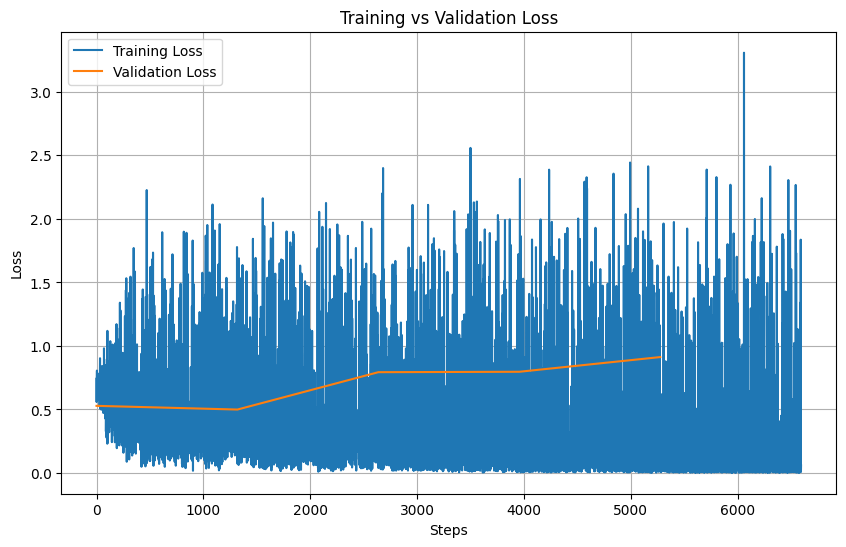

In [33]:
from matplotlib import pyplot as plt
plt.figure(figsize=(10, 6))
plt.plot(train_loss, label='Training Loss')
plt.plot(range(0, len(train_loss), len(train_loss)//len(val_loss)), val_loss, label='Validation Loss')
plt.title('Training vs Validation Loss')
plt.xlabel('Steps')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

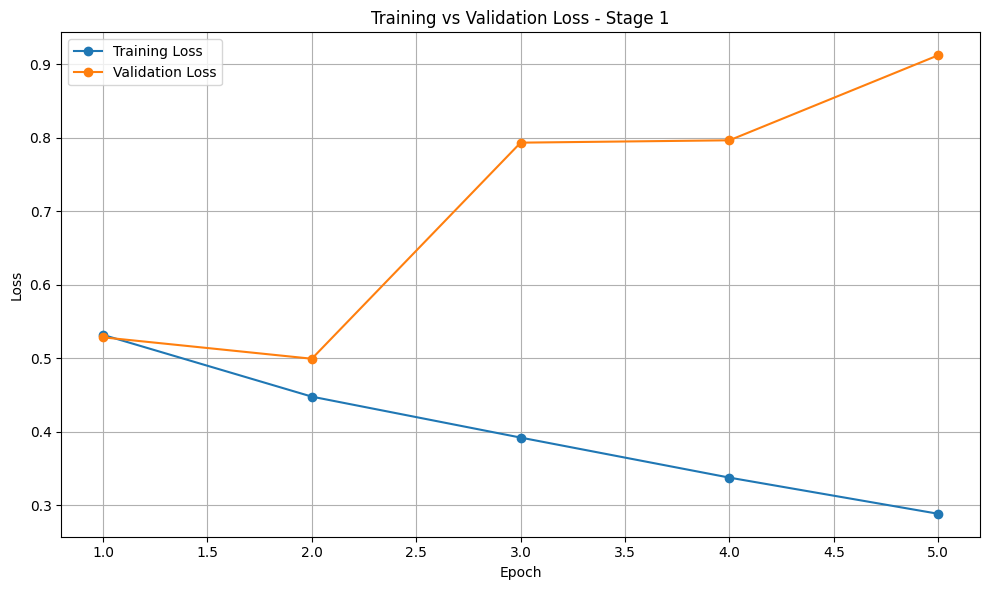

In [1]:
import matplotlib.pyplot as plt
import numpy as np

history_s1 = trainer_s1.state.log_history

# =========================
# Training Loss
# =========================

train_logs_s1 = [
    x for x in history_s1
    if 'loss' in x and 'eval_loss' not in x
]

train_epochs_s1 = [x['epoch'] for x in train_logs_s1]
train_losses_s1 = [x['loss'] for x in train_logs_s1]

# Kelompokkan training loss berdasarkan epoch
epoch_numbers_s1 = sorted(
    set(int(np.ceil(e)) for e in train_epochs_s1)
)

avg_train_loss_s1 = []

for epoch in epoch_numbers_s1:
    losses = [
        loss
        for e, loss in zip(train_epochs_s1, train_losses_s1)
        if int(np.ceil(e)) == epoch
    ]

    avg_train_loss_s1.append(np.mean(losses))


# =========================
# Validation Loss
# =========================

val_logs_s1 = [
    x for x in history_s1
    if 'eval_loss' in x
]

# Ambil validation loss PERTAMA untuk setiap epoch
val_loss_by_epoch_s1 = {}

for x in val_logs_s1:
    epoch = int(round(x['epoch']))

    if epoch not in val_loss_by_epoch_s1:
        val_loss_by_epoch_s1[epoch] = x['eval_loss']

val_epochs_s1 = sorted(val_loss_by_epoch_s1.keys())

val_losses_s1 = [
    val_loss_by_epoch_s1[epoch]
    for epoch in val_epochs_s1
]

plt.figure(figsize=(10, 6))

plt.plot(epoch_numbers_s1, avg_train_loss_s1, marker='o', label='Training Loss')
plt.plot(val_epochs_s1, val_losses_s1, marker='o', label='Validation Loss')
plt.title('Training vs Validation Loss - Stage 1')
plt.xlabel('Epoch')
plt.ylabel('Loss')

plt.legend()
plt.grid(True)
plt.tight_layout()

plt.show()

In [34]:
evaluation_results1 = trainer_s1.evaluate()
print(evaluation_results1)

{'eval_loss': 0.501554548740387, 'eval_accuracy': 0.8663760424564063, 'eval_f1': 0.4819985304922851, 'eval_recall': 0.6833333333333333, 'eval_precision': 0.37230419977298523, 'eval_roc_auc': 0.7840144564915207, 'eval_runtime': 29.3993, 'eval_samples_per_second': 179.46, 'eval_steps_per_second': 11.225, 'epoch': 5.0}


In [35]:
pred1 = trainer_s1.predict(test_dataset_1)
pred_label1 = pred1.predictions.argmax(axis=1)

y_test_numeric = y_test

print(classification_report(y_test_numeric, pred_label1))

              precision    recall  f1-score   support

           0       0.97      0.88      0.92      4796
           1       0.37      0.68      0.48       480

    accuracy                           0.87      5276
   macro avg       0.67      0.78      0.70      5276
weighted avg       0.91      0.87      0.88      5276



# stage 2

In [36]:
df_toxic = df_main[df_main["toxicity"] == 1].copy()

In [37]:
LABEL_COLS = [
    "insults",
    "identity_attack",
    "threat_incitement_to_violence",
    "profanity_obscenity",
    "sexually_explicit"
]

X = df_toxic["processed_text"]
y2 = df_toxic[LABEL_COLS]

In [38]:
train_df_s2, test_df_s2 = train_test_split(
    df_toxic,
    test_size=0.2,
    random_state=42
)

train_df_s2 = train_df_s2[["processed_text"] + LABEL_COLS].copy()
test_df_s2 = test_df_s2[["processed_text"] + LABEL_COLS].copy()

train_df_s2["label"] = train_df_s2[LABEL_COLS].astype(float).values.tolist()
test_df_s2["label"] = test_df_s2[LABEL_COLS].astype(float).values.tolist()

train_df_s2 = train_df_s2[["processed_text", "label"]]
test_df_s2 = test_df_s2[["processed_text", "label"]]

In [39]:
# Handle imbalance for Stage 2 (multi-label) via per-label class weights, used by a
# weighted BCEWithLogitsLoss (pos_weight) below.
train_labels_s2 = np.array(train_df_s2["label"].tolist())
pos_counts_s2 = train_labels_s2.sum(axis=0)
neg_counts_s2 = train_labels_s2.shape[0] - pos_counts_s2
pos_weight_s2 = torch.tensor(neg_counts_s2 / pos_counts_s2, dtype=torch.float)
print("Stage 2 class weights per label:", dict(zip(LABEL_COLS, pos_weight_s2.tolist())))

Stage 2 class weights per label: {'insults': 1.2927120923995972, 'identity_attack': 1.4138364791870117, 'threat_incitement_to_violence': 20.561798095703125, 'profanity_obscenity': 5.527210712432861, 'sexually_explicit': 37.380001068115234}


In [40]:
dataset_s2 = DatasetDict({
    "train": Dataset.from_pandas(train_df_s2.reset_index(drop=True)),
    "test": Dataset.from_pandas(test_df_s2.reset_index(drop=True))
})

In [41]:
MODEL_NAME = "indolem/indobertweet-base-uncased"

tokenizer_s2 = AutoTokenizer.from_pretrained(
    MODEL_NAME
)

In [42]:
def tokenize_s2(batch):
    return tokenizer_s2(
        batch["processed_text"],
        padding="max_length",
        truncation=True,
        max_length=128
    )

tokenized_datasets_2 = dataset_s2.map(
    tokenize_s2,
    batched=True
)

tokenized_datasets_2 = tokenized_datasets_2.remove_columns(
    ["processed_text"]
)

tokenized_datasets_2 = tokenized_datasets_2.rename_column(
    "label",
    "labels"
)

tokenized_datasets_2.set_format("torch")
train_dataset_2 = tokenized_datasets_2["train"]
test_dataset_2 = tokenized_datasets_2["test"]

Map:   0%|          | 0/1919 [00:00<?, ? examples/s]

Map:   0%|          | 0/480 [00:00<?, ? examples/s]

In [43]:
model_s2 = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=len(LABEL_COLS),
    problem_type="multi_label_classification"
)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

In [44]:
import numpy as np
from sklearn.metrics import f1_score, roc_auc_score


def compute_metrics_s2(eval_pred):
    logits, labels = eval_pred


    preds = (logits > 0).astype(int)

    return {
        "f1_micro": f1_score(labels, preds, average="micro"),
        "f1_macro": f1_score(labels, preds, average="macro"),
        "accuracy": accuracy_score(labels, preds),
        "recall_micro": recall_score(
            labels,
            preds,
            average="micro",
            zero_division=0
        ),

        "precision_micro": precision_score(
            labels,
            preds,
            average="micro",
            zero_division=0
        )

    }

In [45]:
# Trainer that applies class weights (pos_weight) to BCEWithLogitsLoss, used to
# handle label imbalance in Stage 2 (multi-label).
class WeightedTrainerMultiLabel(Trainer):
    def __init__(self, *args, pos_weight=None, **kwargs):
        super().__init__(*args, **kwargs)
        self.pos_weight = pos_weight

    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        logits = outputs.logits
        weight = self.pos_weight.to(logits.device) if self.pos_weight is not None else None
        loss_fct = nn.BCEWithLogitsLoss(pos_weight=weight)
        loss = loss_fct(logits, labels.float())
        return (loss, outputs) if return_outputs else loss

In [46]:
args_s2 = TrainingArguments(
    output_dir="./baseline_s2",
    num_train_epochs=5,
    logging_steps=1,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    learning_rate = 1e-5,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    disable_tqdm=False
)

trainer_s2 = WeightedTrainerMultiLabel(
    model=model_s2,
    args=args_s2,
    train_dataset=train_dataset_2,
    eval_dataset=test_dataset_2,
    compute_metrics=compute_metrics_s2,
    pos_weight=pos_weight_s2
)

In [47]:
trainer_s2.train()

Epoch,Training Loss,Validation Loss,F1 Micro,F1 Macro,Accuracy,Recall Micro,Precision Micro
1,0.696697,0.890612,0.540091,0.447458,0.185417,0.697266,0.440741
2,0.577452,0.808059,0.569963,0.481312,0.200000,0.759766,0.456038
3,0.719505,0.776963,0.582298,0.501624,0.243750,0.732422,0.483247
4,0.669660,0.770583,0.597970,0.524395,0.270833,0.748047,0.498049
5,0.542370,0.758164,0.584712,0.520896,0.264583,0.724609,0.490092


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=600, training_loss=0.8053241889675459, metrics={'train_runtime': 188.3584, 'train_samples_per_second': 50.94, 'train_steps_per_second': 3.185, 'total_flos': 631154644235520.0, 'train_loss': 0.8053241889675459, 'epoch': 5.0})

In [48]:
history_s2 = trainer_s2.state.log_history
train_loss_s2 = [x['loss'] for x in history_s2 if 'loss' in x]
val_loss_s2 = [x['eval_loss'] for x in history_s2 if 'eval_loss' in x]
epochs_s2 = [x['epoch'] for x in history_s2 if 'eval_loss' in x]

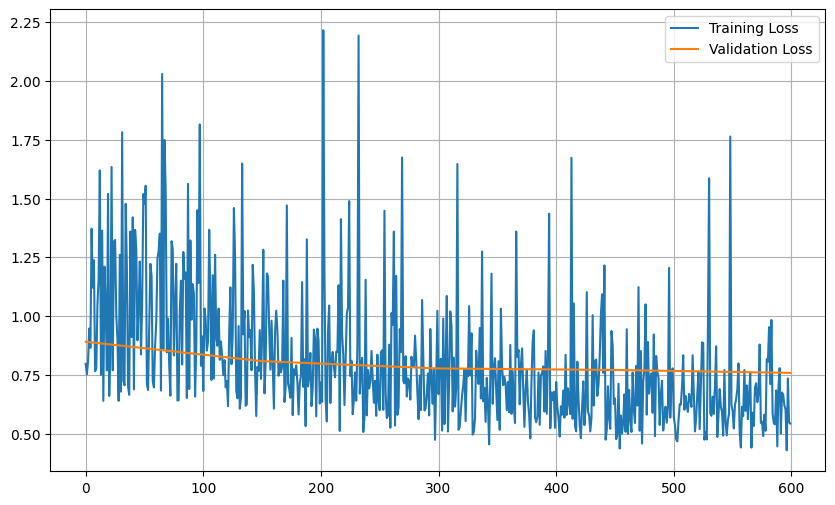

In [49]:
plt.figure(figsize=(10, 6))

plt.plot(train_loss_s2, label='Training Loss')

plt.plot(
    np.linspace(0, len(train_loss_s2)-1, len(val_loss_s2)),
    val_loss_s2,
    label='Validation Loss'
)

plt.legend()
plt.grid(True)
plt.show()

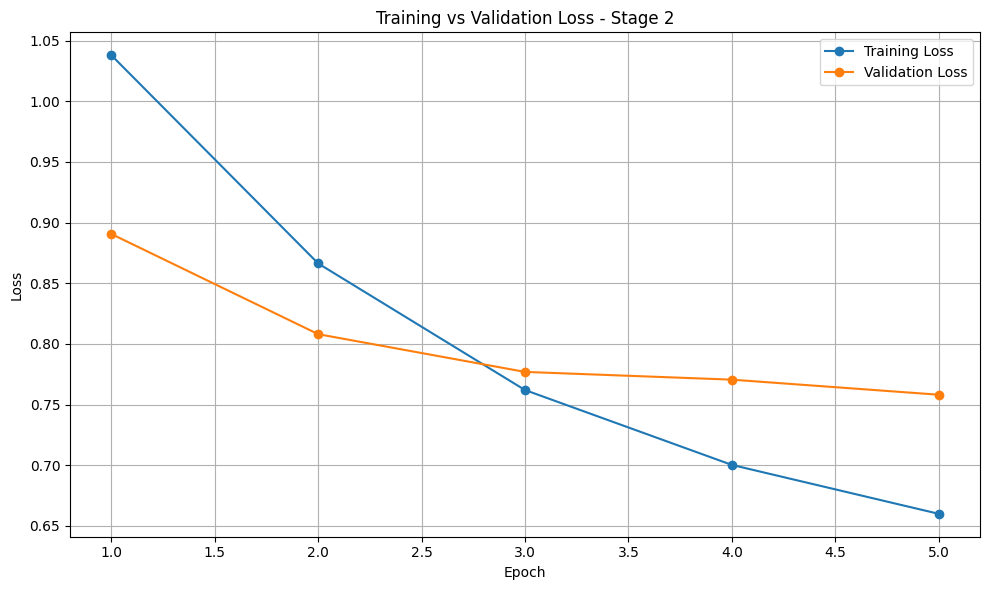

In [2]:
import matplotlib.pyplot as plt
import numpy as np

history_s2 = trainer_s2.state.log_history

# =========================
# Training Loss
# =========================

train_logs_s2 = [
    x for x in history_s2
    if 'loss' in x and 'eval_loss' not in x
]

train_epochs_s2 = [x['epoch'] for x in train_logs_s2]
train_losses_s2 = [x['loss'] for x in train_logs_s2]

# Kelompokkan training loss berdasarkan epoch
epoch_numbers_s2 = sorted(
    set(int(np.ceil(e)) for e in train_epochs_s2)
)

avg_train_loss_s2 = []

for epoch in epoch_numbers_s2:
    losses = [
        loss
        for e, loss in zip(train_epochs_s2, train_losses_s2)
        if int(np.ceil(e)) == epoch
    ]

    avg_train_loss_s2.append(np.mean(losses))


# =========================
# Validation Loss
# =========================

val_logs_s2 = [
    x for x in history_s2
    if 'eval_loss' in x
]

# Ambil validation loss PERTAMA untuk setiap epoch
val_loss_by_epoch_s2 = {}

for x in val_logs_s2:
    epoch = int(round(x['epoch']))

    if epoch not in val_loss_by_epoch_s2:
        val_loss_by_epoch_s2[epoch] = x['eval_loss']

val_epochs_s2 = sorted(val_loss_by_epoch_s2.keys())

val_losses_s2 = [
    val_loss_by_epoch_s2[epoch]
    for epoch in val_epochs_s2
]

plt.figure(figsize=(10, 6))
plt.plot( epoch_numbers_s2, avg_train_loss_s2, marker='o', label='Training Loss')
plt.plot(val_epochs_s2, val_losses_s2, marker='o', label='Validation Loss')
plt.title('Training vs Validation Loss - Stage 2')
plt.xlabel('Epoch')
plt.ylabel('Loss')

plt.legend()
plt.grid(True)
plt.tight_layout()

plt.show()

In [50]:
evaluation_results2 = trainer_s2.evaluate()
print(evaluation_results2)

{'eval_loss': 0.7581642270088196, 'eval_f1_micro': 0.5847123719464145, 'eval_f1_macro': 0.5208956114690502, 'eval_accuracy': 0.26458333333333334, 'eval_recall_micro': 0.724609375, 'eval_precision_micro': 0.4900924702774108, 'eval_runtime': 2.7154, 'eval_samples_per_second': 176.767, 'eval_steps_per_second': 11.048, 'epoch': 5.0}


In [51]:
pred2 = trainer_s2.predict(test_dataset_2)

In [52]:
logits = pred2.predictions

probs = 1 / (1 + np.exp(-logits))

threshold = 0.5
pred_label2 = (probs > threshold).astype(int)

y_true = pred2.label_ids

print(classification_report(y_true, pred_label2, target_names=LABEL_COLS))

                               precision    recall  f1-score   support

                      insults       0.60      0.71      0.65       218
              identity_attack       0.56      0.74      0.64       199
threat_incitement_to_violence       0.10      0.58      0.17        19
          profanity_obscenity       0.45      0.74      0.56        65
            sexually_explicit       0.45      0.82      0.58        11

                    micro avg       0.49      0.72      0.58       512
                    macro avg       0.43      0.72      0.52       512
                 weighted avg       0.54      0.72      0.61       512
                  samples avg       0.51      0.63      0.54       512



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in samples with no predicted labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in samples with no true labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in samples with no true nor predicted labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [53]:
for i, label_name in enumerate(LABEL_COLS):

    print(f"\n===== {label_name} =====")

    print(
        classification_report(
            y_true[:, i],
            pred_label2[:, i]
        )
    )


===== insults =====
              precision    recall  f1-score   support

         0.0       0.71      0.60      0.65       262
         1.0       0.60      0.71      0.65       218

    accuracy                           0.65       480
   macro avg       0.66      0.66      0.65       480
weighted avg       0.66      0.65      0.65       480


===== identity_attack =====
              precision    recall  f1-score   support

         0.0       0.76      0.58      0.66       281
         1.0       0.56      0.74      0.64       199

    accuracy                           0.65       480
   macro avg       0.66      0.66      0.65       480
weighted avg       0.68      0.65      0.65       480


===== threat_incitement_to_violence =====
              precision    recall  f1-score   support

         0.0       0.98      0.79      0.88       461
         1.0       0.10      0.58      0.17        19

    accuracy                           0.78       480
   macro avg       0.54      0.69  